# Model Training 2 - Random Forest Regressor
#### Using the [yggdrasil-decision-forest (ydf)](https://ydf.readthedocs.io/en/stable/py_api/RandomForestLearner/) library

## 1. Feature Selection / Data Tuning

In [ ]:
# import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
import ydf
import matplotlib.pyplot as plt
import plotly
from IPython.display import HTML
import seaborn as sns
import numpy as np
%matplotlib inline

In [57]:
# read train and test data
train_df = pd.read_csv('../Data/Train.csv')
test_df = pd.read_csv('../Data/Test.csv')

In [58]:
# function to plot model evaluation
sns.set_theme(style="whitegrid")

def plot_model_evaluation(y_true, y_pred, title="Model Evaluation"):
    """
    Plot residual, prediction, and ground truth diagnostics for regression models.
    
    Parameters:
        y_true (array-like): Ground truth values
        y_pred (array-like): Model predictions
        title (str): Title of the overall plot
    """
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    residuals = y_pred - y_true

    # Create figure layout
    fig, axs = plt.subplots(3, 2, figsize=(14, 14))
    fig.suptitle(title, fontsize=16)

    # 1. Residual Histogram
    sns.histplot(residuals, bins=60, ax=axs[0, 0], color="C0")
    axs[0, 0].set_title("Residual Histogram")
    axs[0, 0].set_xlabel("Residual")
    axs[0, 0].set_ylabel("Density")

    # 2. Ground Truth Histogram
    sns.histplot(y_true, bins=60, ax=axs[0, 1], color="C0")
    axs[0, 1].set_title("Ground Truth Histogram")
    axs[0, 1].set_xlabel("Ground truth")
    axs[0, 1].set_ylabel("Density")

    # 3. Prediction Histogram
    sns.histplot(y_pred, bins=60, ax=axs[1, 0], color="C0")
    axs[1, 0].set_title("Prediction Histogram")
    axs[1, 0].set_xlabel("Prediction")
    axs[1, 0].set_ylabel("Density")

    # 4. Ground Truth vs Predictions (binned)
    df_gt_pred = pd.DataFrame({"ground_truth": y_true, "prediction": y_pred})
    df_gt_pred["gt_bin"] = pd.cut(df_gt_pred["ground_truth"], bins=30)
    binned_gt = df_gt_pred.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["prediction"], label="Prediction", color="darkorange")
    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["ground_truth"], linestyle="--", color="C0", label="Ideal")
    axs[1, 1].set_title("Ground Truth vs Predictions (Binned)")
    axs[1, 1].set_xlabel("Ground Truth")
    axs[1, 1].set_ylabel("Prediction")
    axs[1, 1].legend()

    # 5. Predictions vs Residual (binned)
    df_pred_res = pd.DataFrame({"prediction": y_pred, "residual": residuals})
    df_pred_res["pred_bin"] = pd.cut(df_pred_res["prediction"], bins=30)
    binned_pred = df_pred_res.groupby("pred_bin", observed=False).mean(numeric_only=True)

    axs[2, 0].plot(binned_pred["prediction"], binned_pred["residual"], color="darkorange")
    axs[2, 0].axhline(0, linestyle="--", color="C0")
    axs[2, 0].set_title("Predictions vs Residual (Binned)")
    axs[2, 0].set_xlabel("Prediction")
    axs[2, 0].set_ylabel("Residual")

    # 6. Ground Truth vs Residual (binned)
    df_gt_res = pd.DataFrame({"ground_truth": y_true, "residual": residuals})
    df_gt_res["gt_bin"] = pd.cut(df_gt_res["ground_truth"], bins=30)
    binned_gt_res = df_gt_res.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[2, 1].plot(binned_gt_res["ground_truth"], binned_gt_res["residual"], color="darkorange")
    axs[2, 1].axhline(0, linestyle="--", color="C0")
    axs[2, 1].set_title("Ground Truth vs Residual (Binned)")
    axs[2, 1].set_xlabel("Ground Truth")
    axs[2, 1].set_ylabel("Residual")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


### Model 1.1 - using all default features
Not use engineered feature 'DAYS_SINCE_LAUNCH' yet

In [59]:
# train model
features1_1 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'EPOCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model1_1 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features1, label='LIFETIME').train(train_df, verbose=2)

Train model on 19579 examples
Model trained in 0:00:14.941832


In [60]:
description1_1 = model1_1.describe()
description1_1

In [61]:
# evaluate the model
evaluation1_1 = model1_1.evaluate(test_df)
print(evaluation1_1)

RMSE: 1451.29
num examples: 4895
num examples (weighted): 4895



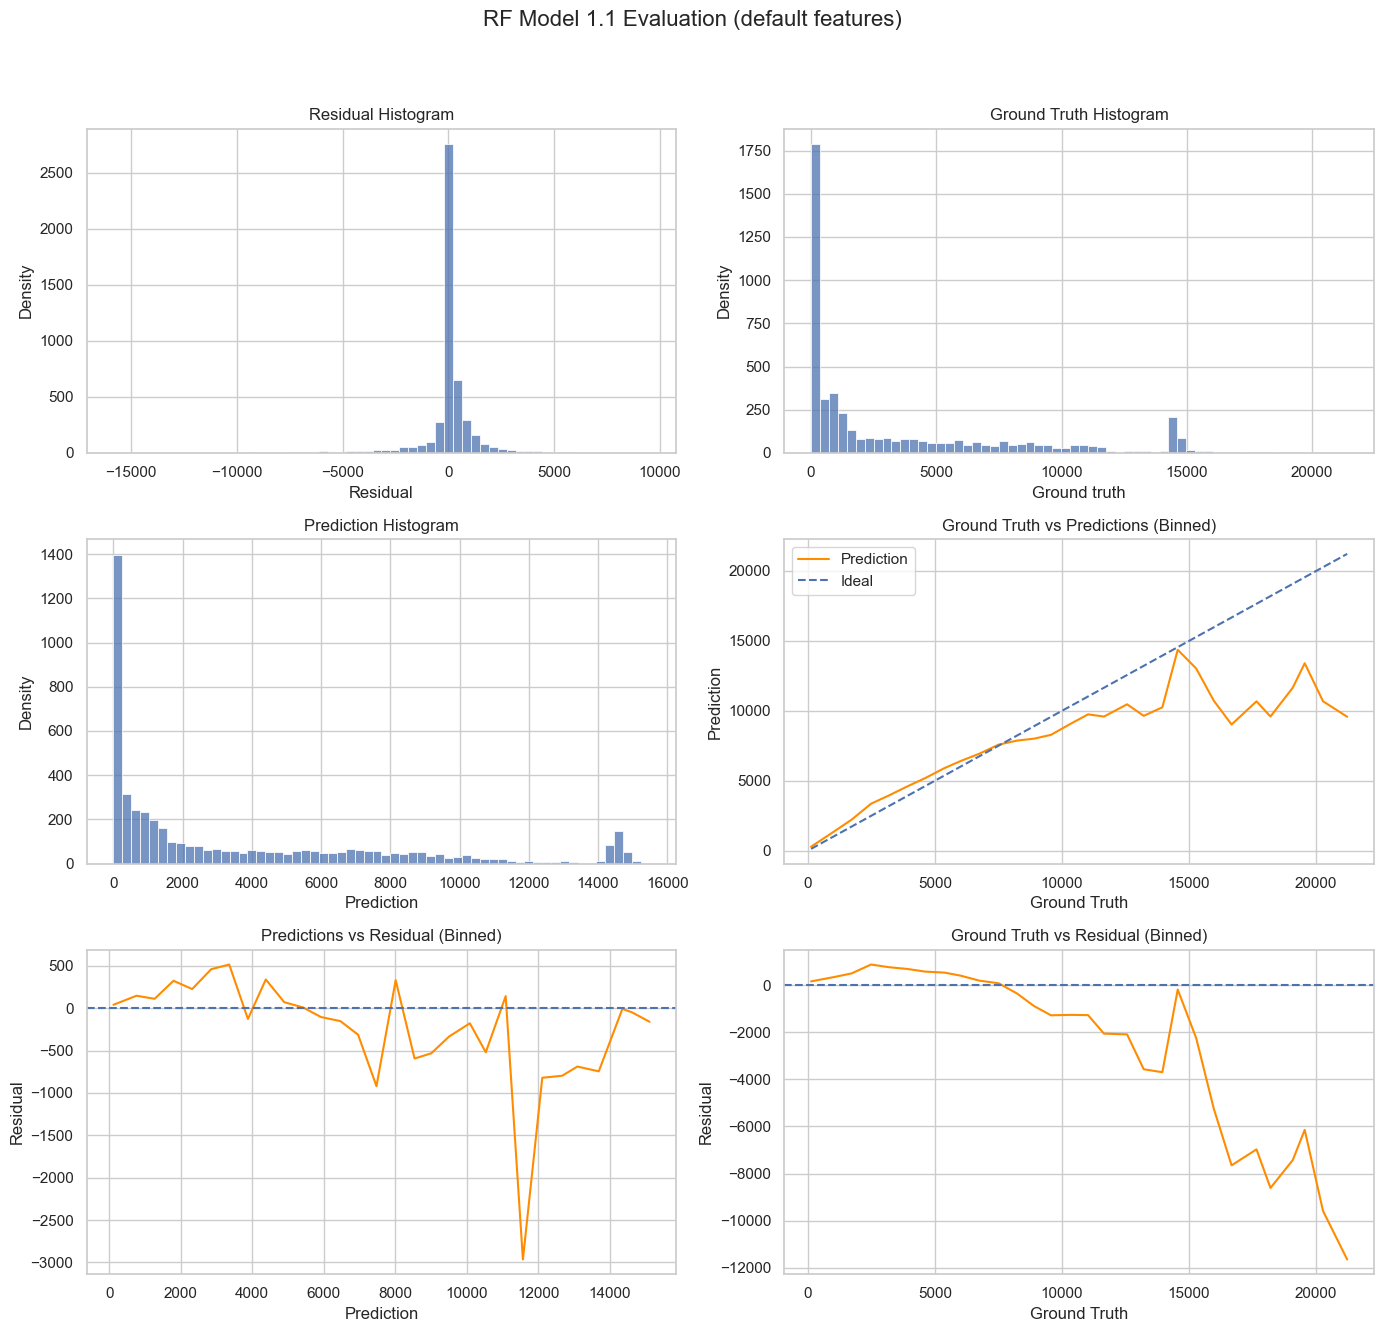

In [62]:
# plot model evaluation
y_true = test_df['LIFETIME']
y_pred1_1 = model1_1.predict(test_df)
plot_model_evaluation(y_true, y_pred1_1, title="RF Model 1.1 Evaluation (default features)")

#### Interpretation Evaluation
1. Residual Histogram: Many Predictions near 0 -> correct, right-side skew -> overestimating<br>
3. Prediction Histogram: Model underestimates the tail (compared to Ground Truth Histogram)<br>
4. Ground Truth vs. Predictions: Good accuracy for small lifetimes (tendency towards overestimating); Starting around 10k–12k, the line begins to flatten → the model underpredicts higher values (except good accuracy for objects with little below 15000 days lifetime, that appear more often in the data)
5. Prediction vs. Residual: near 0 residuals for low predictions -> good fit, as predictions increase the residuals increase sharply -> possibly missclassifies low-GT samples as high one

In [63]:
# analyze the model
analysis1_1 = model1_1.analyze(test_df)
analysis1_1

#### Interpretation Analysis
Partial Dependence Plots:
- Rocket bodies decay faster on average than debris
- Country and Site have a significant (yet not physical) impact on lifetime as well, distribution very imbalanced (CIS/US and TTMTR/PKMTR most represented)
- Periapsis: the lower the periapsis the shorter the lifetime -> low orbits decay faster
- Mean Motion: higher mean motion -> lower orbit -> stronger drag -> shorter lifetime
- Revolution at Epoch: higher revs -> longer lifetime
- BSTAR: counterintuitive, higher drag should lead to objects decaying faster
- Semimajor Axis: the shorter the shorter the lifetime (measure for altitude)
- Mean Motion Dot: for most objects between 0 and 0.01
- Period: the longer the longer the lifetime

In [ ]:
# save the model
model1_1.save('../Models/RF1_1.ydf')

### Model 1.2 - using all features 
Including engineered feature 'DAYS_SINCE_LAUNCH'

In [65]:
# train model
features1_2 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'EPOCH', 'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model1_2 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features1_2, label='LIFETIME').train(train_df, verbose=2)

Train model on 19579 examples
Model trained in 0:00:17.627655


In [66]:
description1_2 = model1_2.describe()
description1_2

In [67]:
# evaluate the model
evaluation1_2 = model1_2.evaluate(test_df)
print(evaluation1_2)

RMSE: 756.904
num examples: 4895
num examples (weighted): 4895



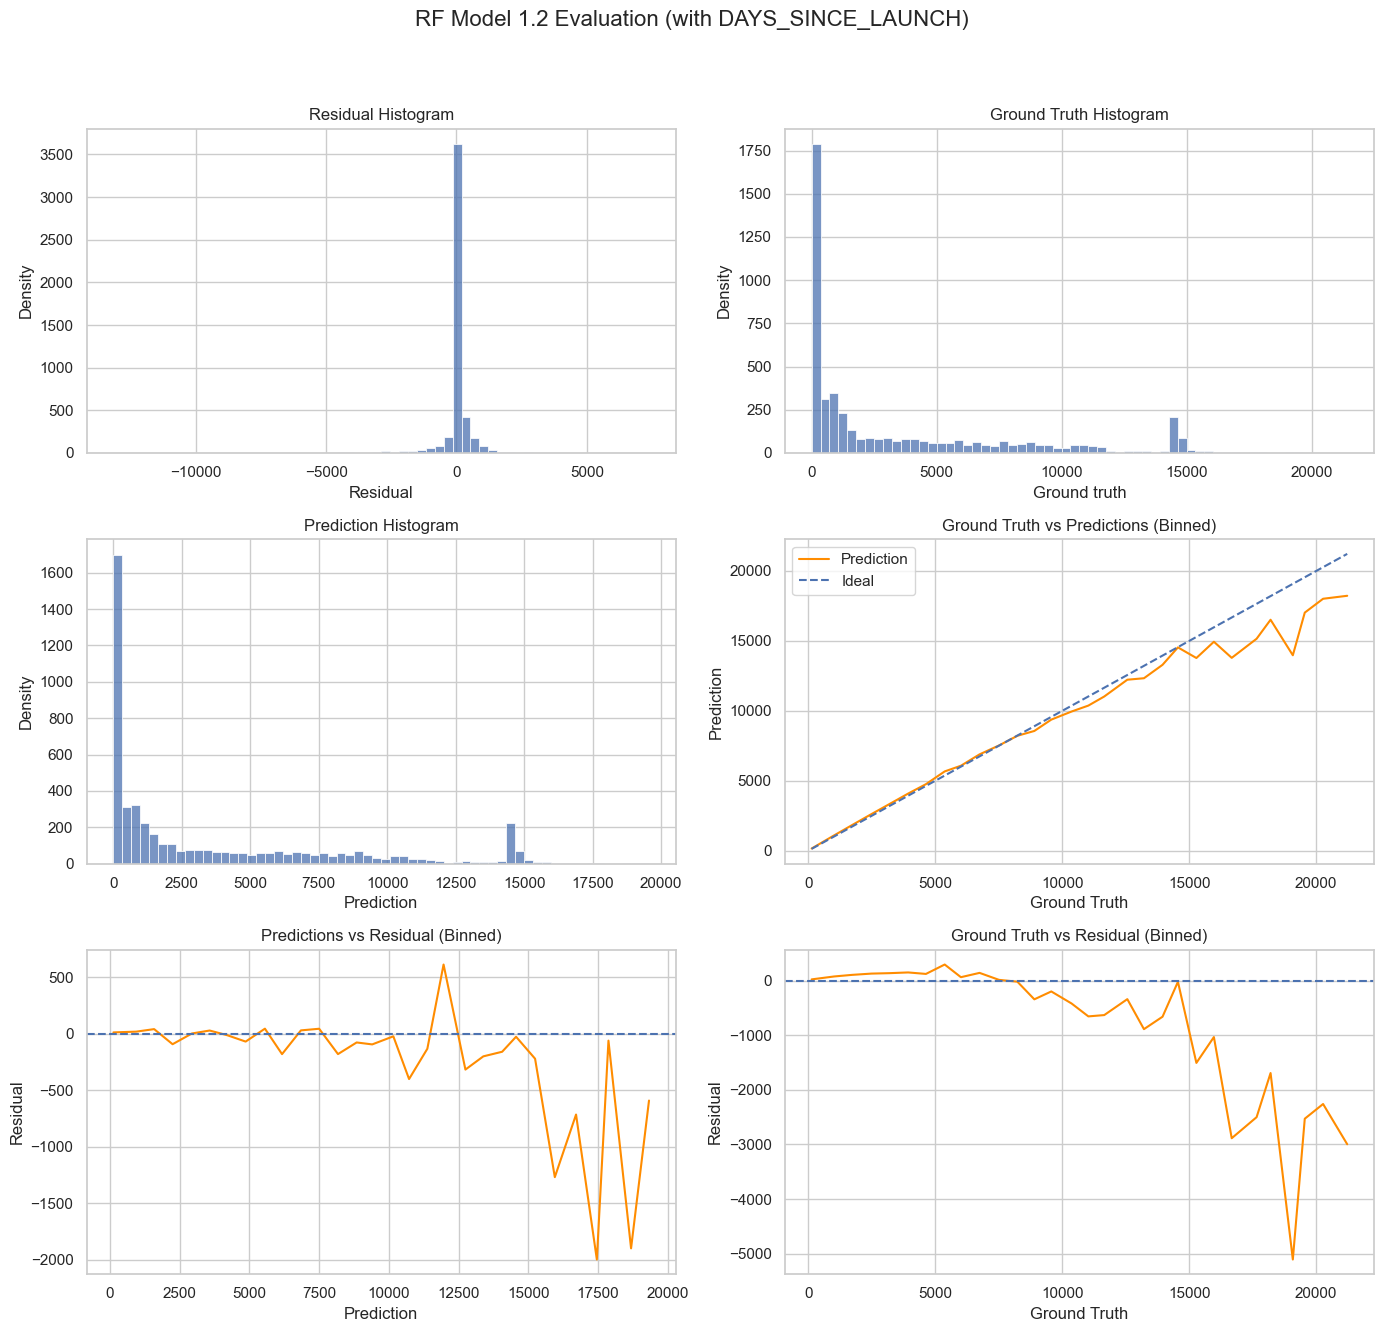

In [68]:
# plot model evaluation
y_pred1_2 = model1_2.predict(test_df)
plot_model_evaluation(y_true, y_pred1_2, title="RF Model 1.2 Evaluation (with DAYS_SINCE_LAUNCH)")

In [69]:
# analyze the model
analysis1_2 = model1_2.analyze(test_df)
analysis1_2

#### Interpretation Analysis
DAYS_SINCE_LAUNCH: Variable importance is not correct, difference from Model 1 (without) and Model 2 (with) is 1451.29 - 756.904 = 694.386 <br>
The feature DAYS_SINCE_LAUNCH significantly improves the performance of the RF because, for many objects with very short lifetimes, the randomly chosen epoch is close to their decay date and thus the lifetime can be inferred from this feature. 

In [ ]:
# save the model
model1_2.save('../Models/RF1_2.ydf')

### Model 3 - Remove not needed features 
(MEAN_ANOMALY, MEAN_MOTION_DDOT, ARG_OF_PERICENTER & EPOCH)

In [71]:
# train model
features1_3 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model1_3 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features1_3, label='LIFETIME').train(train_df, verbose=2)

Train model on 19579 examples
Model trained in 0:00:18.545340


In [72]:
# describe model
description1_3 = model1_3.describe()
description1_3

In [ ]:
# show rmse
evaluation1_3 = model1_3.evaluate(test_df)
print(evaluation1_3)

RMSE: 756.894
num examples: 4895
num examples (weighted): 4895



#### RSME only got marginally better (0.01)

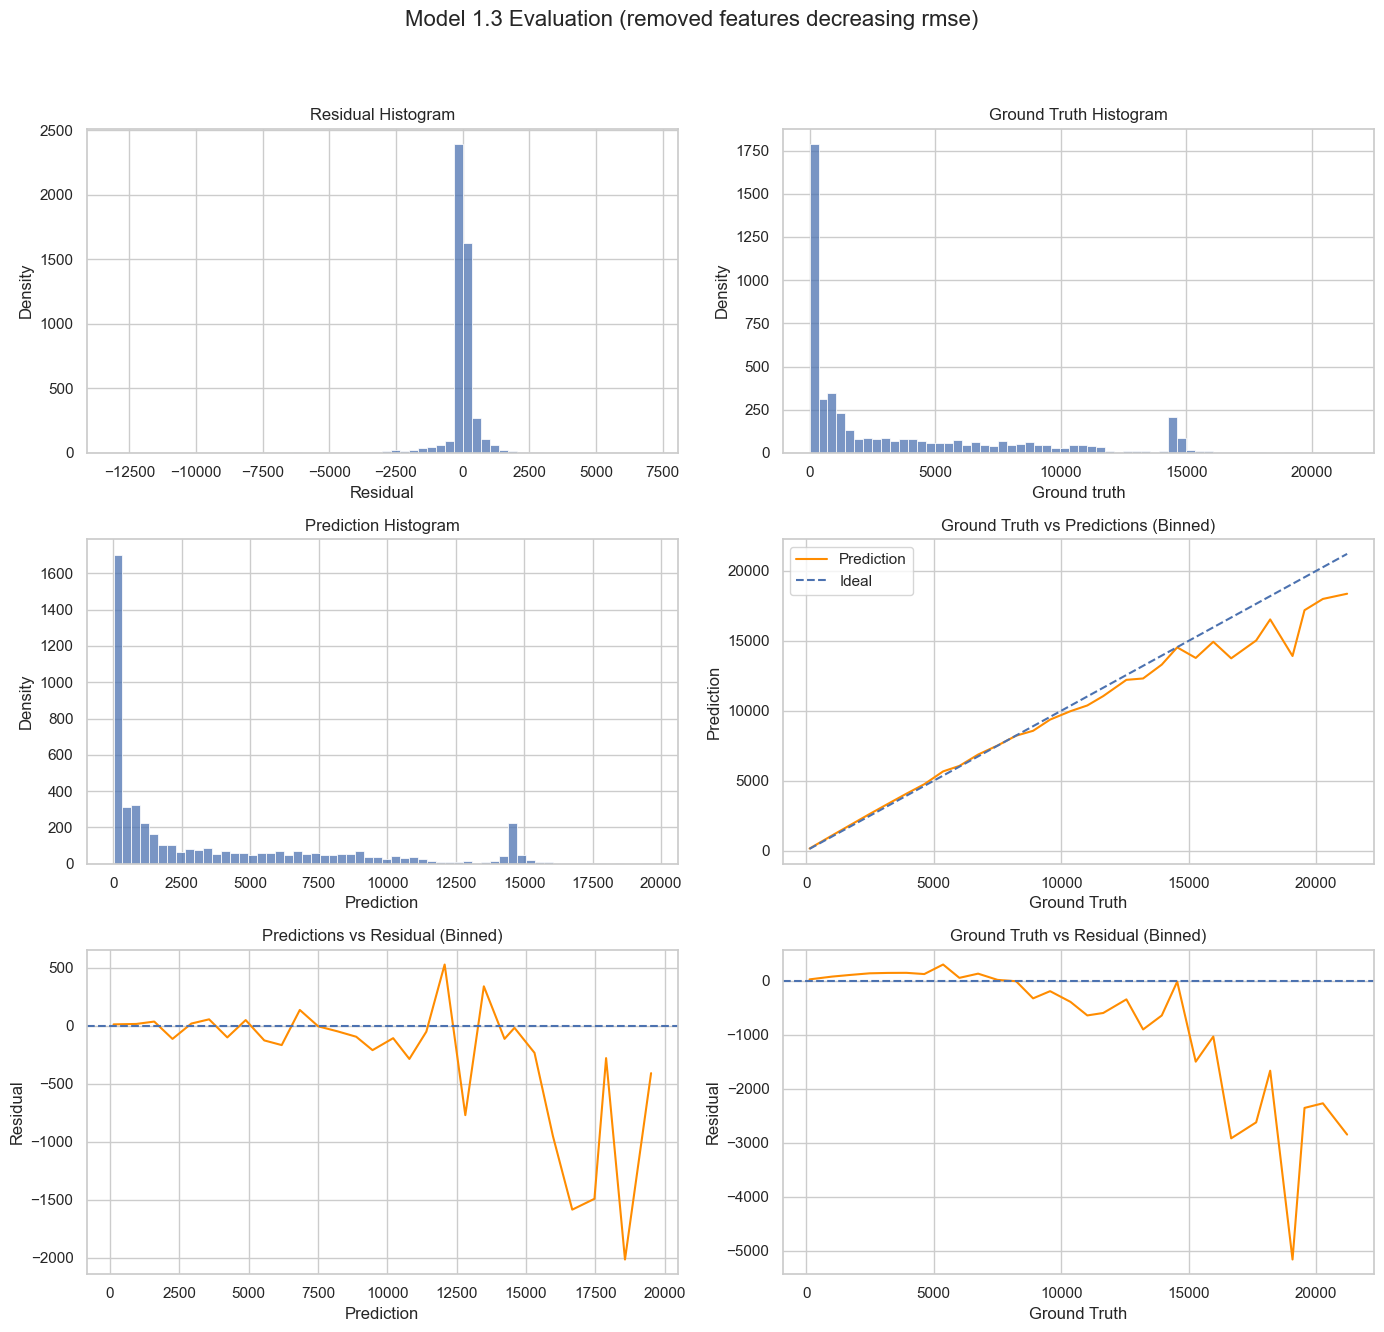

In [74]:
# evaluate modely_pred2 = model2.predict(test_df)
y_pred1_3 = model1_3.predict(test_df)
plot_model_evaluation(y_true, y_pred1_3, title="Model 1.3 Evaluation (removed features decreasing rmse)")

In [75]:
# analyze the model
analysis1_3 = model1_3.analyze(test_df)
analysis1_3

In [76]:
# save model
model1_3.save('../Models/RF1_3.ydf')

## 2. Hyperparameter Tuning